<a href="https://colab.research.google.com/github/sajeeshmily/Intro/blob/main/digit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training AI model...
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9274 - loss: 0.2546
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9675 - loss: 0.1103
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9772 - loss: 0.0759
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9826 - loss: 0.0565
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9862 - loss: 0.0444
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9776 - loss: 0.0756

Model Accuracy: 97.76 %
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Actual Digit: 7
Predicted Digit: 7


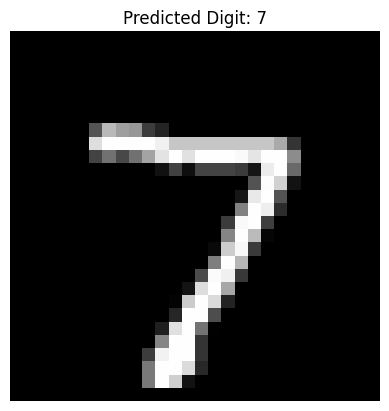

In [1]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Step 1: Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

# Step 2: Normalize image data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 3: Create Neural Network
model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Step 4: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 5: Train the model
print("\nTraining AI model...")

model.fit(x_train, y_train, epochs=5)

# Step 6: Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 7: Predict a handwritten digit
predictions = model.predict(x_test)

# Select an image
index = 0

predicted_digit = predictions[index].argmax()

print("\nActual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)

# Step 8: Display the image and prediction
plt.imshow(x_test[index], cmap='gray')
plt.title("Predicted Digit: " + str(predicted_digit))
plt.axis('off')
plt.show()


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8734 - loss: 0.4198 - val_accuracy: 0.9376 - val_loss: 0.2004
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9350 - loss: 0.2112 - val_accuracy: 0.9591 - val_loss: 0.1297
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9483 - loss: 0.1723 - val_accuracy: 0.9638 - val_loss: 0.1216
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9551 - loss: 0.1467 - val_accuracy: 0.9682 - val_loss: 0.1086
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9590 - loss: 0.1319 - val_accuracy: 0.9580 - val_loss: 0.1462
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9595 - loss: 0.1290
Test Accuracy: 95.95000147819519 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


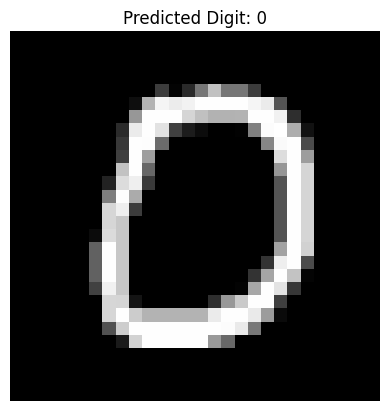

In [6]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# 2. Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Build neural network
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Data augmentation
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    layers.Flatten(),

    # Hidden layers
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Output layer
    layers.Dense(10, activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
model.fit(
    x_train.reshape(-1, 28, 28, 1),
    y_train,
    epochs=5,
    validation_split=0.2
)

# 6. Evaluate model
loss, accuracy = model.evaluate(
    x_test.reshape(-1, 28, 28, 1), y_test
)

print("Test Accuracy:", accuracy * 100, "%")

# 7. Predict a digit
index = 10

image = x_test[index]

prediction = model.predict(image.reshape(1, 28, 28, 1))

predicted_digit = np.argmax(prediction)

# 8. Display result
plt.imshow(image, cmap='gray')
plt.title("Predicted Digit: " + str(predicted_digit))
plt.axis('off')
plt.show()
